In [1]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

In [2]:
from typing import Optional
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def insert_image(ax, path: str, zoom: float = 0.1, pos: tuple[float, float] = (0.0, 0.0), color: Optional[np.ndarray] = None):
    '''
    '''
    
    # load image
    img = mpimg.imread(path)
    
    # if desired, recolour
    if color is not None:
        img[(img != 0).any(axis = -1)] = color
    
    # make image
    icon = OffsetImage(img, zoom = zoom)
    
    box = AnnotationBbox(
        icon,
        pos,
        xycoords = ax.transAxes,
        frameon = False
    )
    
    # add to axis
    ax.add_artist(box)

/var/folders/b4/qysvl6jd4995kp_qql3yj3880000gn/T/ipykernel_15055/663117541.py:339: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  benefit = np.exp(benefit) / np.exp(benefit).sum(axis = 0, keepdims = True)


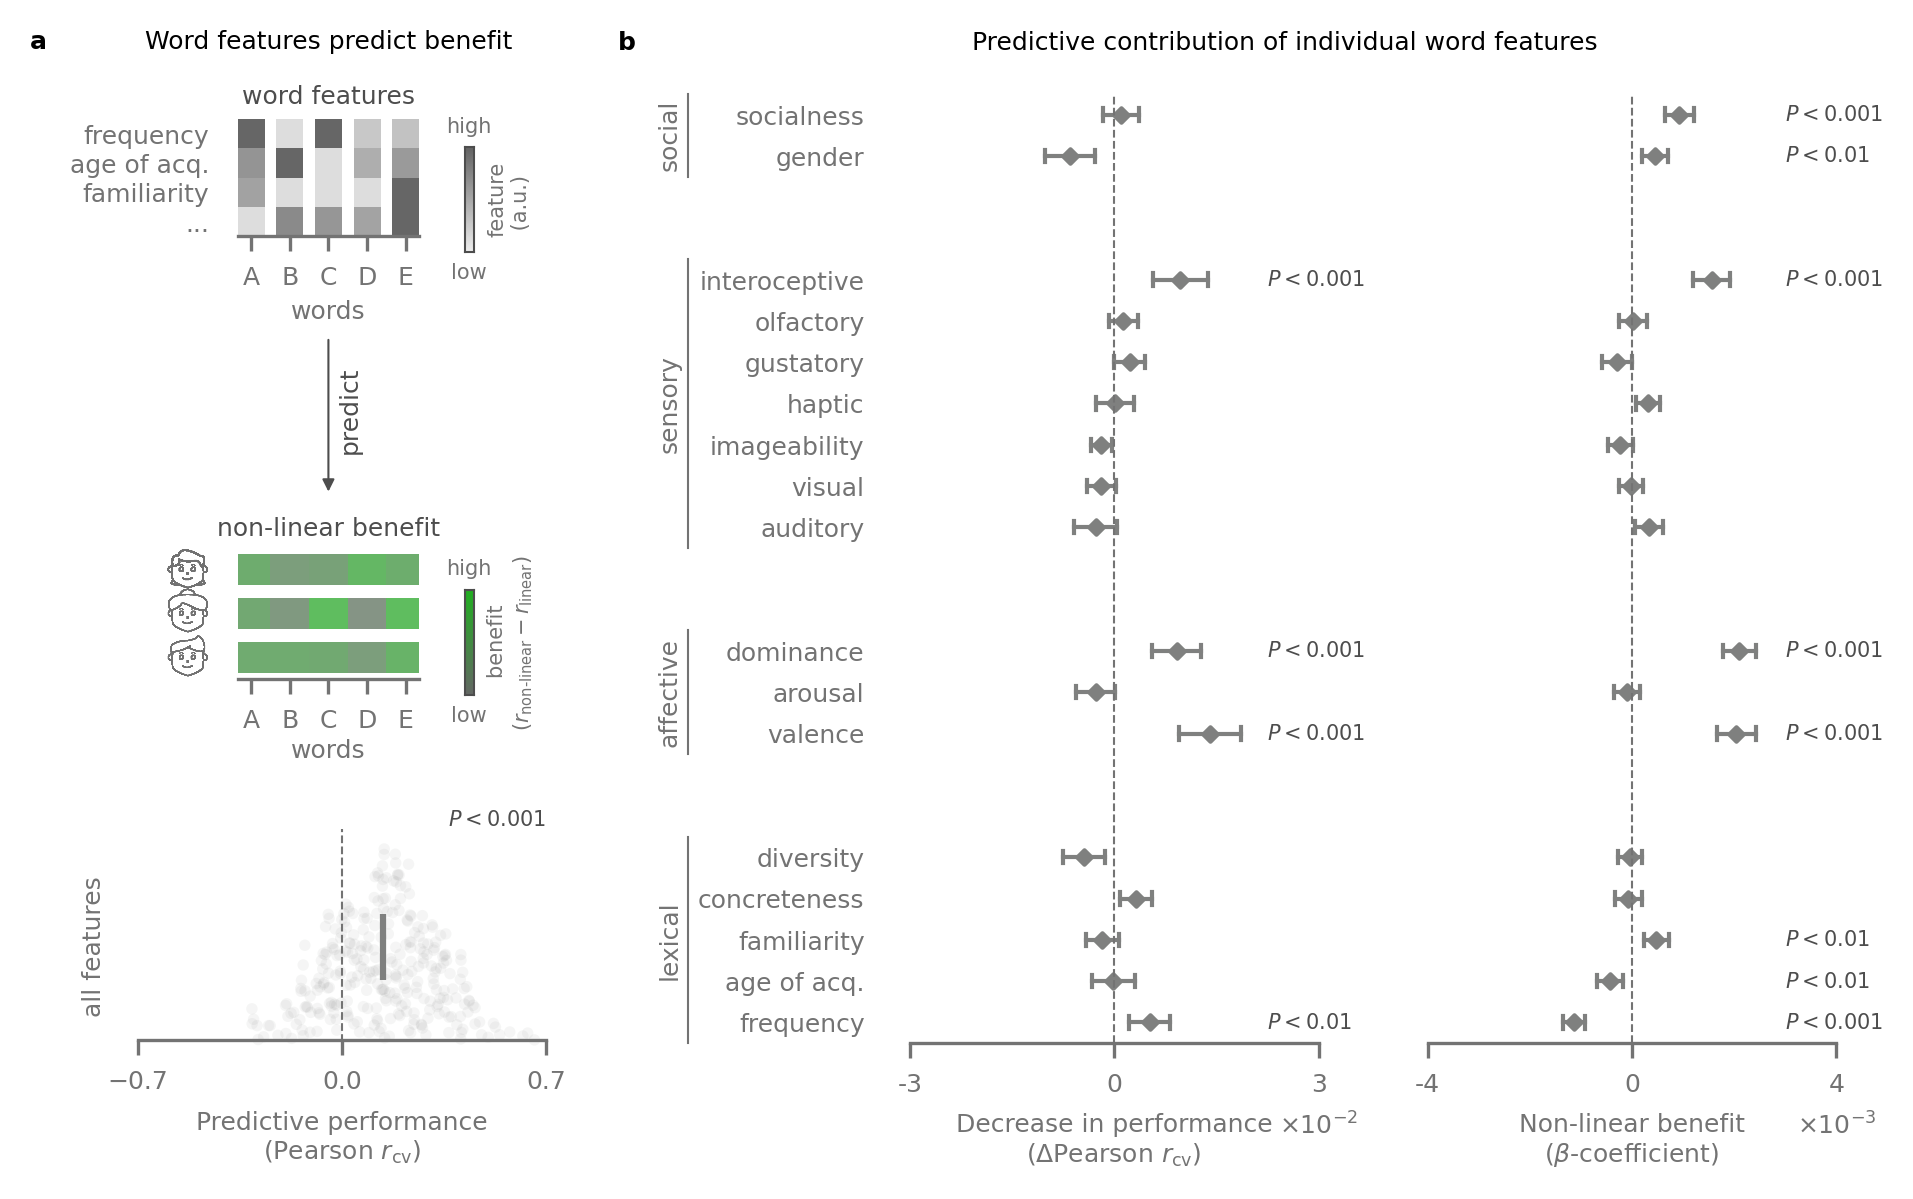

In [131]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

exp = 2
run = 6
emb = 'glove'
compute_stat = True

cols = np.array([
    plots.colours.HL_EMBEDDING,
    plots.colours.HL_OTHERS,
    plots.colours.HL_SELF
])

hypothesis_test = 'sign'
hypothesis_alternative = 'two-sided'
hypothesis_method = 'holm'
hypothesis_se = 'within'

fig, ax = plt.subplots(figsize = (6.40, 4.0), dpi = 300)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.axis('off')

outputs = torch.load(
    f'../data/ds-exp2/derivatives/run-00{run}/tasks/task-maspace_bse0-{emb}_mod-delta.pt', 
    map_location = torch.device('cpu'),
    weights_only = False
)

'''
panel B + C
'''

ax3 = ax.inset_axes([0.465, 0.05, 0.225, 0.90])
ax4 = ax.inset_axes([0.750, 0.05, 0.225, 0.90])

# right panel
perf = outputs['S3_r_full'][emb].mean(0)
redu = (perf[None,:] - outputs['S3_r_redu'][emb].mean(1))
mu1 = redu.mean(1)
se1 = model.stats.bootstrap_se(redu.mT)
if compute_stat:
    stat_p3 = model.stats.sample_tests(perf[None,:], popmean = 0.0, test = 'sign', alternative = 'greater', method = 'holm', se = 'between')
    stat_r3 = model.stats.sample_tests(redu, popmean = 0.0, test = 'sign', alternative = 'greater', method = 'holm', se = 'between')
    model.stats.save_results(stat_p3, f'./deliverable/csv/fig6/b_perf.csv')
    model.stats.save_results(stat_r3, f'./deliverable/csv/fig6/b_redu.csv')
    
coef = outputs['S3_ß_full'][emb].mean(0).mT
mu2 = coef.mean(1)
se2 = model.stats.bootstrap_se(coef.mT)
if compute_stat:
    stat_c3 = model.stats.sample_tests(coef, popmean = 0.0, test = 'sign', alternative = 'two-sided', method = 'holm', se = 'between')
    model.stats.save_results(stat_c3, f'./deliverable/csv/fig6/b_coef.csv')

yoff = 0.15

labels = np.array([
      "frequency", "aoa", "concreteness", "valence", "arousal", "dominance", 
      "imageability", "familiarity", "gender", "auditory", "gustatory",
      "haptic", "interoceptive", "olfactory", "visual", "socialness",
      "diversity"
])

relabel = dict(
    aoa = 'age of acq.'
)

groups = dict(
    lexical = [
        'frequency', 'aoa', 'familiarity', 'concreteness', 'diversity'
    ],
    affective = [
        'valence', 'arousal', 'dominance',
    ],
    sensory = [
        'auditory', 'visual', 'imageability', 'haptic', 'gustatory', 'olfactory', 'interoceptive',
    ],
    social = [
        'gender', 'socialness'
    ]
)

c = 0
yticks = []
yticklabels = []
rowspacing = 2.0
groupspacing = -6.35e-2

for i, key in enumerate(groups):
    labels_i = groups[key]
    
    pre_c = deepcopy(c)
    for j, label_j in enumerate(labels_i):
        indx = np.where(labels == label_j)[0][0].item()
        
        if label_j in relabel:
            label_j = relabel[label_j]
        
        # part B
        ax3.scatter([mu1[indx]], [c], color = cols[1], marker = 'D', s = 6)
        ax3.plot([mu1[indx] - 1.96 * se1[indx], mu1[indx] + 1.96 * se1[indx]], [c, c], color = cols[1], lw = 1.0)
        ax3.plot([mu1[indx] - 1.96 * se1[indx], mu1[indx] - 1.96 * se1[indx]], [c - yoff, c + yoff], color = cols[1], lw = 1.0)
        ax3.plot([mu1[indx] + 1.96 * se1[indx], mu1[indx] + 1.96 * se1[indx]], [c - yoff, c + yoff], color = cols[1], lw = 1.0)
        min_p = stat_r3[indx]['p_cor']

        if min_p <= 0.05:
            sig = fr'$P < 0.001$' if min_p < 0.001 else fr'$P < 0.01$' if min_p < 0.01 else fr'$P < 0.05$' if min_p <= 0.05 else 'n.s.'

            ax3.annotate(
                sig,
                xy = (0, 0),
                xytext = (2.25e-2, c),
                ha = 'left',
                va = 'center',
                fontsize = 5,
                color = plots.colours.H2,
                annotation_clip = False
            )
        
        
        # part C
        ax4.scatter([mu2[indx]], [c], color = cols[1], marker = 'D', s = 6)
        ax4.plot([mu2[indx] - 1.96 * se2[indx], mu2[indx] + 1.96 * se2[indx]], [c, c], color = cols[1], lw = 1.0)
        ax4.plot([mu2[indx] - 1.96 * se2[indx], mu2[indx] - 1.96 * se2[indx]], [c - yoff, c + yoff], color = cols[1], lw = 1.0)
        ax4.plot([mu2[indx] + 1.96 * se2[indx], mu2[indx] + 1.96 * se2[indx]], [c - yoff, c + yoff], color = cols[1], lw = 1.0)
        min_p = stat_c3[indx]['p_cor']

        if min_p <= 0.05:
            sig = fr'$P < 0.001$' if min_p < 0.001 else fr'$P < 0.01$' if min_p < 0.01 else fr'$P < 0.05$' if min_p <= 0.05 else 'n.s.'

            ax4.annotate(
                sig,
                xy = (0, 0),
                xytext = (3.0e-3, c),
                ha = 'left',
                va = 'center',
                fontsize = 5,
                color = plots.colours.H2,
                annotation_clip = False
            )
        
        yticks.append(c)
        yticklabels.append(label_j)
        c += 1
    
    
    post_c = deepcopy(c - 1)
    mc = pre_c + (post_c - pre_c) / 2
    
    ax3.plot([groupspacing + 0.1e-2, groupspacing + 0.1e-2], [pre_c - 0.5, post_c + 0.5], lw = 0.5, ls = '-', color = plots.colours.H3, clip_on = False)
    
    ax3.annotate(
        key,
        xy = (0, 0),
        xytext = (groupspacing, mc),
        ha = 'right',
        va = 'center',
        rotation = 90,
        fontsize = 6,
        color = plots.colours.H3,
        annotation_clip = False
    )
    
    c += rowspacing

sns.despine(ax = ax3)
sns.despine(ax = ax4)    

ax3.plot([0, 0], [-0.5, c - rowspacing - 0.5], color = plots.colours.H3, lw = 0.5, ls = '--')
ax4.plot([0, 0], [-0.5, c - rowspacing - 0.5], color = plots.colours.H3, lw = 0.5, ls = '--')

ax3.set_xlim([-3e-2, 3e-2])
ax3.set_xticks([-3e-2, 0, 3e-2], labels = ['-3', '0', '3'])
ax3.set_xlabel('Decrease in performance\n' + fr'($\Delta$Pearson $r_{{\text{{cv}}}}$)')
ax3.set_ylim([-0.5, c - rowspacing - 0.5])
ax3.set_yticks(yticks, labels = yticklabels)
ax3.spines['left'].set_position(('axes', -0.075))
ax3.spines['left'].set_visible(False)
ax3.tick_params(axis = 'y', which = 'both', length = 0)

ax4.set_xlim([-4e-3, 4e-3])
ax4.set_xticks([-4e-3, 0, 4e-3], labels = ['-4', '0', '4'])
ax4.set_xlabel('Non-linear benefit\n' + fr'($\beta$-coefficient)')
ax4.set_yticks([])
ax4.set_ylim([-0.5, c - rowspacing - 0.5])
ax4.spines['left'].set_position(('axes', -0.075))
ax4.spines['left'].set_visible(False)
ax4.tick_params(axis = 'y', which = 'both', length = 0)

ax3.annotate(
    fr'$\times10^{{-2}}$',
    xy = (0, 0),
    xytext = (3e-2, -2.5),
    ha = 'center',
    va = 'center',
    fontsize = 6,
    color = plots.colours.H3,
    annotation_clip = False
)

ax4.annotate(
    fr'$\times10^{{-3}}$',
    xy = (0, 0),
    xytext = (4e-3, -2.5),
    ha = 'center',
    va = 'center',
    fontsize = 6,
    color = plots.colours.H3,
    annotation_clip = False
)

'''
panel A (schematic)
'''

# left side
#ax9 = ax.inset_axes([0.085, 0.815, 0.10, 0.125])
ax9 = ax.inset_axes([0.095, 0.815, 0.10, 0.125])

words = [
    'A', 'B', 'C', 'D', 'E'
]

domains = [
    '...', 'familiarity', 'age of acq.', 'frequency'
]

loading = np.random.uniform(low = 0, high = 1, size = (len(words), len(domains)))

colors = loading - loading.min(axis = 0, keepdims = True)
colors = colors / colors.max(axis = 0, keepdims = True)

T = 1.0
loading = np.exp(loading / T) / np.exp(loading / T).sum(axis = 1, keepdims = True)
n_w = len(words)
n_d = len(domains)
ioff = 0.35
joff = 0.50

for i in range(n_w):
    for j in range(n_d):
        ax9.fill_between(
            [i - ioff, i + ioff],
            j - joff, j + joff,
            facecolor = plots.colours.CM_RDM_CL(min(1 - colors[i,j], 0.85)),#cols[1],
            edgecolor = 'None'
        )

ax9.annotate(
    'word features',
    xy = (0, 0),
    xytext = (2.0, 3.85),
    ha = 'center',
    va = 'bottom',
    fontsize = 6,
    color = plots.colours.H2
)

ax9.set_xticks(np.arange(n_w), labels = words)
ax9.set_xlabel(fr'words', labelpad = 2.5)
ax9.set_xlim([-0.35, n_w - 0.65])
ax9.set_yticks(np.arange(n_d), labels = domains)
ax9.set_ylim([-0.50, n_d])

sns.despine(ax = ax9)

ax9.spines['left'].set_position(('axes', -0.075))
ax9.spines['left'].set_visible(False)
ax9.tick_params(axis = 'y', which = 'both', length = 0)

#cm = ax.inset_axes([0.210, 0.800, 0.005, 0.10])
cm = ax.inset_axes([0.220, 0.800, 0.005, 0.10])
cm.set_xlim([0, 1])
cm.set_ylim([0, 1])
cm.axis('off')

x = np.ones((100,)) * 0.5
y = np.linspace(0, 1, 100)
z = np.linspace(0, 1, 100)

cm.scatter(x, y, color = plots.colours.CM_RDM_CL(1 - z), marker = '.', s = 3)
cm.plot([0, 1], [0, 0], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm.plot([0, 1], [1, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm.plot([0, 0], [0, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm.plot([1, 1], [0, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)

cm.annotate(
    'low',
    xy = (0, 0),
    xytext = (0.5, -0.1),
    ha = 'center',
    va = 'top',
    fontsize = 5,
    color = plots.colours.H3
)

cm.annotate(
    'high',
    xy = (0, 0),
    xytext = (0.5, 1.1),
    ha = 'center',
    va = 'bottom',
    fontsize = 5,
    color = plots.colours.H3
)


cm.annotate(
    'feature\n (a.u.)',
    xy = (0, 0),
    xytext = (2.50, 0.5),
    ha = 'left',
    va = 'center',
    fontsize = 5,
    color = plots.colours.H3,
    rotation = 90
)

# right side
#ax10 = ax.inset_axes([0.085, 0.545, 0.10, 0.125])
ax10 = ax.inset_axes([0.095, 0.395, 0.10, 0.125])

benefit = outputs['S3_D'][emb]['y'][0:n_w,0:3]
benefit = np.exp(benefit) / np.exp(benefit).sum(axis = 0, keepdims = True)
benefit -= benefit.min()
benefit = benefit / benefit.max()
benefit = 0.15 + benefit * 0.75

ioff = 0.35
joff = 0.50

for i in range(benefit.shape[1]):
    for j in range(n_w):
        ax10.fill_between(
            [j - joff, j + joff],
            i - ioff, i + ioff,
            facecolor = plots.colours.CM_RDM_HL(benefit[j,i]),#min(1 - benefit[j,i], 0.85)),#cols[1],
            edgecolor = 'None',
            alpha = 0.75
        )
    
    off = 0.175
    dist = 1 / (benefit.shape[1])
    insert_image(ax10, f'./resources/human-{i+1}.png', 0.04, (-0.275, off + dist * i), color = plots.colours.H3)

ax10.annotate(
    'non-linear benefit',
    xy = (0, 0),
    xytext = (2.0, 2.65),
    ha = 'center',
    va = 'bottom',
    fontsize = 6,
    color = plots.colours.H2
)    

ax10.set_xticks(np.arange(n_w), labels = words)
ax10.set_xlabel(fr'words', labelpad = 1.5)
ax10.set_xlim([-0.35, n_w - 0.65])
ax10.set_yticks([])
ax10.set_ylim([-0.50, benefit.shape[1] - 0.50])

sns.despine(ax = ax10)

ax10.spines['left'].set_position(('axes', -0.075))
ax10.spines['left'].set_visible(False)
ax10.tick_params(axis = 'y', which = 'both', length = 0)

#cm2 = ax.inset_axes([0.210, 0.530, 0.005, 0.10])
cm2 = ax.inset_axes([0.220, 0.380, 0.005, 0.10])
cm2.set_xlim([0, 1])
cm2.set_ylim([0, 1])
cm2.axis('off')

x = np.ones((100,)) * 0.5
y = np.linspace(0, 1, 100)
z = np.linspace(0, 1, 100)

cm2.scatter(x, y, color = plots.colours.CM_RDM_HL(z), marker = '.', s = 3, alpha = 0.75)
cm2.plot([0, 1], [0, 0], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm2.plot([0, 1], [1, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm2.plot([0, 0], [0, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)
cm2.plot([1, 1], [0, 1], color = plots.colours.H2, clip_on = False, lw = 0.5)

cm2.annotate(
    'low',
    xy = (0, 0),
    xytext = (0.5, -0.1),
    ha = 'center',
    va = 'top',
    fontsize = 5,
    color = plots.colours.H3
)

cm2.annotate(
    'high',
    xy = (0, 0),
    xytext = (0.5, 1.1),
    ha = 'center',
    va = 'bottom',
    fontsize = 5,
    color = plots.colours.H3
)


cm2.annotate(
    '        benefit\n' + fr'($r_{{\text{{non-linear}}}} - r_{{\text{{linear}}}}$)',
    xy = (0, 0),
    xytext = (2.50, 0.5),
    ha = 'left',
    va = 'center',
    fontsize = 5,
    color = plots.colours.H3,
    rotation = 90
)

# add connection
"""
ax9.annotate(
    '',
    xy = (7.75, 0.75),
    xytext = (7.75, -8.5),
    ha = 'center',
    va = 'center',
    arrowprops = dict(
        arrowstyle = '<|-',
        connectionstyle = 'bar,fraction=0.15',
        shrinkA = 0,
        shrinkB = 0,
        color = plots.colours.H2,
        lw = 0.5
    ),
    annotation_clip = False
)

ax9.annotate(
    'predict',
    xy = (0, 0),
    xytext = (8.10, -3.875),
    ha = 'center',
    va = 'center',
    fontsize = 6,
    color = plots.colours.H2,
    annotation_clip = False,
    rotation = 90
)
"""

ax9.annotate(
    '',
    xy = (2.0, -3.75),
    xytext = (2.0, -9.5),
    ha = 'center',
    va = 'center',
    arrowprops = dict(
        arrowstyle = '<|-',
        color = plots.colours.H2,
        lw = 0.5
    ),
    annotation_clip = False
)

ax9.annotate(
    'predict',
    xy = (0, 0),
    xytext = (2.55, -6.425),
    ha = 'center',
    va = 'center',
    fontsize = 6,
    color = plots.colours.H2,
    annotation_clip = False,
    rotation = 90
)

'''
panel A (data)
'''

ax5 = ax.inset_axes([0.040, 0.0525, 0.225, 0.20])

X_jitter = np.random.uniform(-0.15, 0.15, size = (303,))
perf = outputs['S3_r_full'][emb].mT.mean(1)
mu = perf.mean()
if compute_stat:
    stat_p = model.stats.sample_tests(perf[None,:], popmean = 0.0, test = 'sign', alternative = 'greater', method = 'holm', se = 'between')
    model.stats.save_results(stat_p, f'./deliverable/csv/fig6/a_group.csv')
min_p = stat_p[0]['p_cor']
sig = fr'$P < 0.001$' if min_p < 0.001 else fr'$P < 0.01$' if min_p < 0.01 else fr'$P < 0.05$' if min_p <= 0.05 else 'n.s.'

#x_i = X_jitter
#ax5.scatter(perf, x_i, marker = '.', edgecolor = 'None', facecolor = cols[1], s = 30, alpha = 0.075, clip_on = False)

from sklearn.neighbors import KernelDensity
perm_pad = 0.0
kde = KernelDensity(bandwidth = 0.01).fit(perf[:,None])
scores = kde.score_samples(perf[:,None])
scores = np.exp(scores)
scores = np.abs(scores / np.trapezoid(scores, perf))
scores = scores / scores.max()
scores = 0.45 * scores - 0.20
x_i = np.array([
    np.random.uniform(low = -0.20, high = scores[i])
    for i in range(len(scores))
])
ax5.scatter(perf, x_i, marker = '.', edgecolor = 'None', facecolor = cols[1], s = 30, alpha = 0.075, clip_on = False)

ax5.scatter([mu], [0], color = cols[1], marker = '|', s = 250, clip_on = False, zorder = 2)
ax5.plot([0, 0], [-0.25, 0.25], color = plots.colours.H3, lw = 0.5, ls = '--')
ax5.annotate(
    sig,
    xy = (0, 0),
    xytext = (0.7, 0.25),
    ha = 'right',
    va = 'bottom',
    fontsize = 5,
    color = plots.colours.H2
)

ax5.set_ylim([-0.2, 0.25])
ax5.set_yticks([])
ax5.set_xlim([-0.7, 0.7])
ax5.set_xticks([-0.7, 0.0, 0.7])
ax5.set_xlabel('Predictive performance\n' + fr'(Pearson $r_{{\text{{cv}}}}$)')

sns.despine(ax = ax5)
ax5.spines['left'].set_position(('axes', -0.075))
ax5.spines['left'].set_visible(False)
ax5.tick_params(axis = 'y', which = 'both', length = 0)

ax5.annotate(
    'all features',
    xy = (0, 0),
    xytext = (-0.850, 0.0),
    fontsize = 6,
    color = plots.colours.H3,
    rotation = 90,
    ha = 'center',
    va = 'center'
)

'''
cosmetics
'''

title_arg = dict(
    xy = (0, 0),
    ha = 'center', 
    va = 'center',
    fontsize = 6,
)

letter_arg = dict(
    **title_arg,
    fontweight = 'bold'
)

#ax3.annotate('b', xytext = (-6.85e-2, c - 1.25), **letter_arg)
ax3.annotate('b', xytext = (-7.15e-2, c - 1.25), **letter_arg)
ax3.annotate('Predictive contribution of individual word features', xytext = (2.5e-2, c - 1.25), **title_arg)

#ax9.annotate('a', xytext = (-5.0, 6.15), **letter_arg)
ax9.annotate('a', xytext = (-5.5, 6.15), **letter_arg)
ax9.annotate('Word features predict benefit', xytext = (2.0, 6.15), **title_arg)

#ax7.annotate('c', xytext = (-0.27, 69.5), **letter_arg)
#ax7.annotate('Individual interests predict domain-specific benefits', xytext = (0.17, 69.5), **title_arg)


# colors
for ax_i in [ax3, ax4, ax9, ax10, ax5]:
    ax_i.yaxis.label.set_color(plots.colours.H3)
    ax_i.xaxis.label.set_color(plots.colours.H3)
    ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', which = 'minor', colors = plots.colours.H3)
    ax_i.tick_params(axis = 'y', which = 'major', colors = plots.colours.H3)
    ax_i.spines['bottom'].set_color(plots.colours.H3)
    ax_i.spines['left'].set_color(plots.colours.H3)

#ax.axis('on')
    
fig.tight_layout()

fig.savefig('./deliverable/png/fig6.png', dpi = 900, format = 'png')
fig.savefig('./deliverable/pdf/fig6.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/fig6.svg', dpi = 900, format = 'svg')